# How a CV PDF is parsed

This notebook follows one fictional CV through the real code in `mycareerai.module.ocr`, one step at a time.

```text
PDF ──> 1. Open and check limits
        2. Try the text layer
        3. Fall back to OCR (render at 300 DPI -> Tesseract)
        4. Clean the text
        5. Split into sections by heading
        6. Pull out contact, experience, education, skills
        7. Build and validate the schema row
```

Run it from the repo root with the project environment (`uv run`). OCR steps need Tesseract (`brew install tesseract`).

## Setup

In [1]:
import re
import tempfile
from pathlib import Path

import pypdfium2
import pytesseract
from IPython.display import Markdown, display
from PIL import Image, ImageDraw, ImageFont

from mycareerai.module.ocr import build_record, extract_text, parse_resume, validate_record
from mycareerai.module.ocr import extract as ex
from mycareerai.module.ocr.resume import (
    HEADINGS, _DATE_RANGE, _DEGREE, _find_email, _find_phone, _find_terms,
    _parse_education, _parse_experience, _parse_skill_lines, split_sections,
)
from mycareerai.module.terms import BULLET, HARD_SKILLS, SOFT_SKILLS


def show(columns, rows):
    clean = lambda value: "–" if value is None else str(value).replace("|", "\\|").replace("\n", " ⏎ ")
    lines = ["| " + " | ".join(columns) + " |", "|" + "---|" * len(columns)]
    lines += ["| " + " | ".join(clean(value) for value in row) + " |" for row in rows]
    display(Markdown("\n".join(lines)))

## The example

The CV is made up for this notebook. It is drawn as an image and saved as a PDF, so it has **no text layer**, like a scanned document. That forces the OCR path.

To try your own CV instead, set `PDF = Path("data/your_cv.pdf")` after this cell.

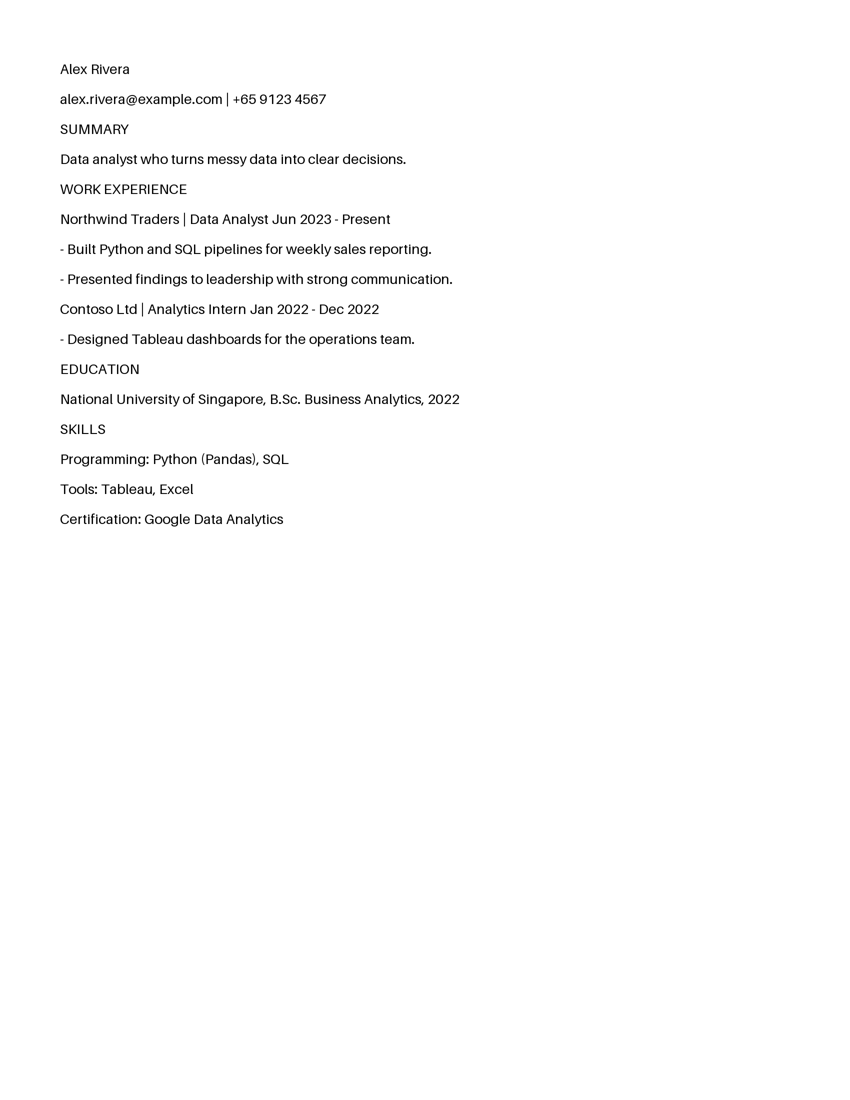

In [2]:
CV_LINES = """Alex Rivera
alex.rivera@example.com | +65 9123 4567
SUMMARY
Data analyst who turns messy data into clear decisions.
WORK EXPERIENCE
Northwind Traders | Data Analyst Jun 2023 - Present
- Built Python and SQL pipelines for weekly sales reporting.
- Presented findings to leadership with strong communication.
Contoso Ltd | Analytics Intern Jan 2022 - Dec 2022
- Designed Tableau dashboards for the operations team.
EDUCATION
National University of Singapore, B.Sc. Business Analytics, 2022
SKILLS
Programming: Python (Pandas), SQL
Tools: Tableau, Excel
Certification: Google Data Analytics""".splitlines()

font = ImageFont.load_default(size=28)
image = Image.new("RGB", (1700, 2200), "white")  # US Letter at 200 DPI
draw = ImageDraw.Draw(image)
for row, line in enumerate(CV_LINES):
    draw.text((120, 120 + row * 60), line, fill="black", font=font)

PDF = Path(tempfile.mkdtemp()) / "alex_rivera_scan.pdf"
image.save(PDF, resolution=200)
image.resize((850, 1100))

## 1. Open the PDF and check the limits

`extract_text` opens the file with pypdfium2 and refuses anything it can't read cheaply. Both checks run **before** any OCR, because OCR takes seconds per page and rendering needs memory in proportion to page area.

In [3]:
document = pypdfium2.PdfDocument(PDF)
page = document[0]
width, height = page.get_size()

show(["Check", "Limit", "This PDF", "OK"], [
    ["Pages", ex.MAX_PAGES, len(document), len(document) <= ex.MAX_PAGES],
    ["Longest page side (points)", ex.MAX_PAGE_POINTS, round(max(width, height)), max(width, height) <= ex.MAX_PAGE_POINTS],
])

| Check | Limit | This PDF | OK |
|---|---|---|---|
| Pages | 5 | 1 | True |
| Longest page side (points) | 1440 | 792 | True |

## 2. Try the text layer first

Most CVs exported from Word or Google Docs carry real text. Reading it is instant and exact, so it's always tried first. If it yields fewer than `MIN_TEXT_LAYER_CHARS` characters, the page counts as a scan.

In [4]:
layer_text = ex._normalise(page.get_textpage().get_text_bounded())
needs_ocr = len(layer_text) < ex.MIN_TEXT_LAYER_CHARS

show(["Text-layer characters", "Threshold", "Use OCR?"], [[len(layer_text), ex.MIN_TEXT_LAYER_CHARS, needs_ocr]])

| Text-layer characters | Threshold | Use OCR? |
|---|---|---|
| 0 | 50 | True |

## 3. Render the page and run Tesseract

The page is rendered at `OCR_DPI` (300). A PDF measures in points, 72 per inch, so the scale is 300 / 72 ≈ 4.17. `--psm 1` tells Tesseract to detect the page layout itself.

scale 4.17 -> 2550 x 3301 pixels


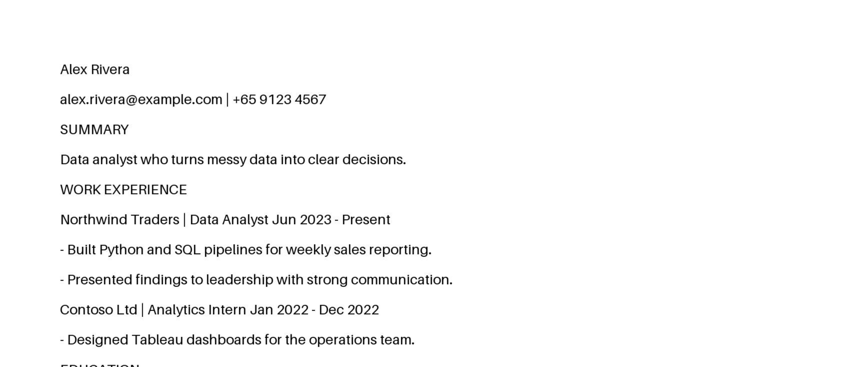

In [5]:
scale = ex.OCR_DPI / ex.PDF_POINTS_PER_INCH
rendered = page.render(scale=scale).to_pil()
print(f"scale {scale:.2f} -> {rendered.size[0]} x {rendered.size[1]} pixels")
rendered.crop((0, 0, rendered.size[0], rendered.size[1] // 3)).resize((850, 367))

In [6]:
raw = pytesseract.image_to_string(rendered, config="--psm 1")
print(raw)

Alex Rivera

alex.rivera@example.com | +65 9123 4567

SUMMARY

Data analyst who turns messy data into clear decisions.

WORK EXPERIENCE

Northwind Traders | Data Analyst Jun 2023 - Present

- Built Python and SQL pipelines for weekly sales reporting.

- Presented findings to leadership with strong communication.
Contoso Ltd | Analytics Intern Jan 2022 - Dec 2022

- Designed Tableau dashboards for the operations team.
EDUCATION

National University of Singapore, B.Sc. Business Analytics, 2022
SKILLS

Programming: Python (Pandas), SQL

Tools: Tableau, Excel

Certification: Google Data Analytics



## 4. Clean the text

`_normalise` collapses runs of spaces and tabs, trims each line and drops blank lines. Then one OCR-specific fix: Tesseract often reads the gap after a bullet as `|`, so `- | Built` becomes `- Built`.

The table shows only the lines that changed.

In [7]:
normalised = ex._normalise(raw)
cleaned = re.sub(r"(?m)^\s*-\s*\|\s*", "- ", normalised)

raw_lines = [line for line in raw.splitlines() if line.strip()]
show(["Raw OCR line", "Cleaned line"], [
    [repr(before), repr(after)] for before, after in zip(raw_lines, cleaned.splitlines()) if before != after
] or [["(no line changed)", ""]])
print(f"{len(raw.splitlines())} raw lines -> {len(cleaned.splitlines())} after dropping blanks")
document.close()

| Raw OCR line | Cleaned line |
|---|---|
| (no line changed) |  |

28 raw lines -> 16 after dropping blanks


True

`extract_text` does steps 1–4 for every page and returns an `ExtractedDocument`. Its `method` is `pdf_text_layer`, `ocr`, or `mixed`, and ends up in the record as `collection_method`.

In [8]:
extracted = extract_text(PDF)
show(["Page", "Method", "Characters"], [[p.number, p.method, len(p.text)] for p in extracted.pages])
show(["Document method", "Same text as steps 1–4"], [[extracted.method, extracted.text == cleaned]])
text = extracted.text

| Page | Method | Characters |
|---|---|---|
| 1 | ocr | 587 |

| Document method | Same text as steps 1–4 |
|---|---|
| ocr | True |

## 5. Split into sections

Parsing is rule-based. A line that matches a known heading from `terms/headings.yaml` (whole line, any case, optional trailing colon) starts a section. Every line after it belongs to that section until the next heading. Lines before the first heading, like the name and contact line, belong to no section.

In [9]:
show(["Line", "Heading?", "Section"], [
    [line, line.strip().rstrip(":").casefold() in HEADINGS, HEADINGS.get(line.strip().rstrip(":").casefold())]
    for line in text.splitlines()
])

| Line | Heading? | Section |
|---|---|---|
| Alex Rivera | False | – |
| alex.rivera@example.com \| +65 9123 4567 | False | – |
| SUMMARY | True | summary |
| Data analyst who turns messy data into clear decisions. | False | – |
| WORK EXPERIENCE | True | experience |
| Northwind Traders \| Data Analyst Jun 2023 - Present | False | – |
| - Built Python and SQL pipelines for weekly sales reporting. | False | – |
| - Presented findings to leadership with strong communication. | False | – |
| Contoso Ltd \| Analytics Intern Jan 2022 - Dec 2022 | False | – |
| - Designed Tableau dashboards for the operations team. | False | – |
| EDUCATION | True | education |
| National University of Singapore, B.Sc. Business Analytics, 2022 | False | – |
| SKILLS | True | skills |
| Programming: Python (Pandas), SQL | False | – |
| Tools: Tableau, Excel | False | – |
| Certification: Google Data Analytics | False | – |

In [10]:
sections = split_sections(text)
show(["Section", "Lines"], [[name, len(lines)] for name, lines in sections.items()])

| Section | Lines |
|---|---|
| summary | 1 |
| experience | 5 |
| education | 1 |
| skills | 3 |

## 6. Pull out the fields

### Contact

Email and phone are searched across the **whole text** with regexes. A phone match must have 8–15 digits and must not be a year range like `2021-2024`.

In [11]:
show(["Field", "Found"], [["email", _find_email(text)], ["phone", _find_phone(text)]])

| Field | Found |
|---|---|
| email | alex.rivera@example.com |
| phone | +65 9123 4567 |

### Work experience

A non-bullet line that ends in a date range (`Jun 2023 - Present`) starts a new role. The text before the dates is split into company and title on `|` (`Company | Title`) or `,` (`Title, Company`). Bullets below it become the description; a line that isn't a bullet is glued onto the previous bullet, since it's a wrapped line.

In [12]:
rows = []
for line in sections["experience"]:
    dates = None if BULLET.match(line) else _DATE_RANGE.search(line)
    kind = "role header" if dates else "bullet" if BULLET.match(line) else "continuation"
    rows.append([line, kind, dates and f"{dates['start']} → {dates['end']}"])
show(["Line", "Read as", "Dates"], rows)

| Line | Read as | Dates |
|---|---|---|
| Northwind Traders \| Data Analyst Jun 2023 - Present | role header | Jun 2023 → Present |
| - Built Python and SQL pipelines for weekly sales reporting. | bullet | – |
| - Presented findings to leadership with strong communication. | bullet | – |
| Contoso Ltd \| Analytics Intern Jan 2022 - Dec 2022 | role header | Jan 2022 → Dec 2022 |
| - Designed Tableau dashboards for the operations team. | bullet | – |

In [13]:
show(["title", "company", "start_date", "end_date", "description"],
     [list(role.values()) for role in _parse_experience(sections["experience"])])

| title | company | start_date | end_date | description |
|---|---|---|---|---|
| Data Analyst | Northwind Traders | Jun 2023 | – | Built Python and SQL pipelines for weekly sales reporting. ⏎ Presented findings to leadership with strong communication. |
| Analytics Intern | Contoso Ltd | Jan 2022 | Dec 2022 | Designed Tableau dashboards for the operations team. |

### Education

Each non-bullet line is searched for a degree (`B.Sc.`, `Master of …`, `PhD`, …). Text before the degree is the institution, text after it is the field of study, and a trailing year is the graduation year.

In [14]:
for line in sections["education"]:
    degree = _DEGREE.search(line)
    print(line)
    print(" " * degree.start() + "^" * (degree.end() - degree.start()) if degree else "(no degree found)")
show(["degree", "institution", "field_of_study", "graduation_year"],
     [list(entry.values()) for entry in _parse_education(sections["education"])])

National University of Singapore, B.Sc. Business Analytics, 2022
                                  ^^^^^


| degree | institution | field_of_study | graduation_year |
|---|---|---|---|
| B.Sc. | National University of Singapore | Business Analytics | 2022 |

### Skills and certifications

Skills come from two places:

1. **Listed skills.** Lines in the skills section are split on `,` `;` and brackets, so `Python (Pandas)` gives two items. A line whose label starts with `Certif` goes to certifications instead.
2. **Vocabulary matches.** Every term in `terms/hard_skills.yaml` and `terms/soft_skills.yaml` is searched across the whole CV, so a skill only mentioned in a bullet still counts.

In [15]:
listed, listed_certs = _parse_skill_lines(sections["skills"])
show(["Source", "Items"], [
    ["Listed in SKILLS", ", ".join(listed)],
    ["Certification line", ", ".join(listed_certs)],
    ["Hard-skill vocabulary hits", ", ".join(_find_terms(text, HARD_SKILLS))],
    ["Soft-skill vocabulary hits", ", ".join(_find_terms(text, SOFT_SKILLS))],
])

| Source | Items |
|---|---|
| Listed in SKILLS | Python, Pandas, SQL, Tableau, Excel |
| Certification line | Google Data Analytics |
| Hard-skill vocabulary hits | Excel, Pandas, Python, SQL, Tableau |
| Soft-skill vocabulary hits | Communication, Leadership |

`parse_resume` does all of step 6 in one call. It also maps listed skills to their canonical vocabulary name and removes duplicates, ignoring case.

In [16]:
fields = parse_resume(text)
show(["Field", "Value"], [[key, value] for key, value in fields.items() if key not in ("work_experience", "education")])

| Field | Value |
|---|---|
| email | alex.rivera@example.com |
| phone | +65 9123 4567 |
| certifications | ['Google Data Analytics'] |
| skills | ['Python', 'Pandas', 'SQL', 'Tableau', 'Excel', 'Communication', 'Leadership'] |
| hard_skills | ['Python', 'Pandas', 'SQL', 'Tableau', 'Excel'] |
| soft_skills | ['Communication', 'Leadership'] |

## 7. Build and validate the record

`build_record` runs everything above and adds the bookkeeping fields: an `id` that is the SHA-256 of the file bytes (so the same PDF always gets the same id), provenance fields, and `None` for the job-description and classification fields that a resume doesn't fill. It then validates the row against `data/schema.yaml` and raises if anything doesn't fit.

In [17]:
record = build_record(PDF, source="notebook example")
show(["Field", "Value"], [[key, value if key != "text" else f"{len(value)} characters"] for key, value in record.items()])

| Field | Value |
|---|---|
| id | 7029cd42d7296032c24dea96df9f435bc154c810f49974858bf76bfa4bc91626 |
| document_type | resume |
| text | 587 characters |
| email | alex.rivera@example.com |
| phone | +65 9123 4567 |
| work_experience | [{'title': 'Data Analyst', 'company': 'Northwind Traders', 'start_date': 'Jun 2023', 'end_date': None, 'description': 'Built Python and SQL pipelines for weekly sales reporting.\nPresented findings to leadership with strong communication.'}, {'title': 'Analytics Intern', 'company': 'Contoso Ltd', 'start_date': 'Jan 2022', 'end_date': 'Dec 2022', 'description': 'Designed Tableau dashboards for the operations team.'}] |
| education | [{'degree': 'B.Sc.', 'institution': 'National University of Singapore', 'field_of_study': 'Business Analytics', 'graduation_year': 2022}] |
| certifications | ['Google Data Analytics'] |
| skills | ['Python', 'Pandas', 'SQL', 'Tableau', 'Excel', 'Communication', 'Leadership'] |
| hard_skills | ['Python', 'Pandas', 'SQL', 'Tableau', 'Excel'] |
| soft_skills | ['Communication', 'Leadership'] |
| responsibilities | – |
| requirements | – |
| qualifications | – |
| occupation | – |
| seniority_level | – |
| industry | – |
| resume_format | – |
| writing_style | – |
| source | notebook example |
| collection_method | ocr |
| license | unknown |
| annotation_method | rule_based |
| review_status | pending |

In [18]:
validate_record(record)  # raises jsonschema.ValidationError on a bad row
print("Record matches data/schema.yaml")

Record matches data/schema.yaml


The same row comes out of the command line:

```bash
uv run python -m mycareerai.module.ocr resume.pdf --output row.json
```